<a href="https://colab.research.google.com/github/ananyaa-sutaria/ML-term-project/blob/role4-transferlearning/04_transfer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

#check if gpu is available
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [3]:
#clone our github repo
!git clone -b role4-transferlearning https://github.com/ananyaa-sutaria/ML-term-project.git

#move into project folder
%cd ML-term-project

#check project files
!ls

Cloning into 'ML-term-project'...
remote: Enumerating objects: 193, done.
remote: Counting objects: 100% (123/123), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 193 (delta 34), reused 66 (delta 21), pack-reused 70 (from 1)
Receiving objects: 100% (193/193), 155.70 MiB | 19.88 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/ML-term-project
01_data.ipynb		 evaluate.py		 requirements.txt
02_traditional_ml.ipynb  experiment1.py		 results
04_transfer.ipynb	 final_submission.ipynb  tests
clean.py		 make_manifest.py	 traditional_model.py
data			 processed
data.py			 README.md


In [5]:
#install kagglehub
!pip -q install kagglehub

#download asl alphabet dataset
import kagglehub

dataset_path = kagglehub.dataset_download("grassknoted/asl-alphabet")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'asl-alphabet' dataset.
Dataset location: /kaggle/input/asl-alphabet


In [6]:
import os

#check dataset folders
print(os.listdir(dataset_path))

['asl_alphabet_test', 'asl_alphabet_train']


In [7]:
import os
from pathlib import Path

#check where the training images are
train_path = Path(dataset_path) / "asl_alphabet_train"
print("Training folder contents:", os.listdir(train_path)[:5])

Training folder contents: ['asl_alphabet_train']


In [8]:
import os

#set the dataset location
os.environ["ASL_DATA_DIR"] = dataset_path

#import our team's data loader
import data

#check the dataset paths
print("Training folder:", data.TRAIN_DIR)
print("Folder exists:", data.TRAIN_DIR.exists())

Training folder: /kaggle/input/asl-alphabet/asl_alphabet_train/asl_alphabet_train
Folder exists: True


In [9]:
#load a small sample of training images
images, labels = data.load_split("train", size=64, color=True, subset="10k")

#check the results
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First label:", labels[0])

Images shape: (10005, 64, 64, 3)
Labels shape: (10005,)
First label: 0


In [10]:
import torch
from torchvision import models
from torch import nn

#load pretrained resnet18
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

#freeze pretrained layers
for param in model.parameters():
    param.requires_grad = False

#replace final layer for 29 asl classes
model.fc = nn.Linear(model.fc.in_features, 29)

#move model to gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Device:", device)
print("Output classes:", model.fc.out_features)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]


Device: cuda
Output classes: 29


In [12]:
import numpy as np
from torchvision import transforms
from PIL import Image

#prepare images for resnet18
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#convert image to uint8
sample = Image.fromarray((np.clip(images[0], 0, 1) * 255).astype(np.uint8))

#apply transforms
sample_tensor = transform(sample)

print("Original image:", images[0].shape)
print("ResNet image:", sample_tensor.shape)

Original image: (64, 64, 3)
ResNet image: torch.Size([3, 224, 224])


In [13]:
#check the shared dataset manifest
manifest = pd.read_csv("processed/asl_alphabet_manifest.csv")

print("Columns:", manifest.columns.tolist())
print()
print(manifest.head())

Columns: ['path', 'label', 'y', 'frame', 'block', 'lighting', 'split', 'subset10k', 'ten_class', 'y10', 'blur_flag', 'confusable_hash']

       path label  y  frame  block lighting  split  subset10k  ten_class  y10  \
0  A/A1.jpg     A  0      1      0   normal  train       True       True    0   
1  A/A2.jpg     A  0      2      0   normal  train      False       True    0   
2  A/A3.jpg     A  0      3      0   normal  train      False       True    0   
3  A/A4.jpg     A  0      4      0   normal  train      False       True    0   
4  A/A5.jpg     A  0      5      0   normal  train      False       True    0   

   blur_flag  confusable_hash  
0      False            False  
1      False            False  
2      False            False  
3      False            False  
4      False            False  


In [14]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

#dataset for loading images in batches
class ASLDataset(Dataset):
    def __init__(self, rows, train_dir, transform):
        self.rows = rows.reset_index(drop=True)
        self.train_dir = train_dir
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows.iloc[idx]

        #load original image
        image_path = self.train_dir / row["path"]
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        #remove blue border
        image = image.crop((4, 4, image.width - 4, image.height - 4))

        image = self.transform(image)
        label = int(row["y"])

        return image, label


#use the team's existing splits
train_rows = manifest[
    (manifest["split"] == "train") &
    (manifest["subset10k"] == True)
]

val_rows = manifest[manifest["split"] == "val"]

train_dataset = ASLDataset(train_rows, data.TRAIN_DIR, transform)
val_dataset = ASLDataset(val_rows, data.TRAIN_DIR, transform)

train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

#test one batch
batch_images, batch_labels = next(iter(train_loader))

print("Batch shape:", batch_images.shape)
print("Labels shape:", batch_labels.shape)

Training images: 10005
Validation images: 9225
Batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])


In [15]:
import torch.optim as optim
import time

#loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

epochs = 5
best_val_accuracy = 0

#track results
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    #training
    model.train()
    train_correct = 0
    train_total = 0
    train_loss = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_correct += (outputs.argmax(1) == batch_labels).sum().item()
        train_total += batch_labels.size(0)

    train_accuracy = train_correct / train_total
    train_accuracies.append(train_accuracy)

    #validation
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)

            val_correct += (outputs.argmax(1) == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_accuracy = val_correct / val_total
    val_accuracies.append(val_accuracy)

    #save best model
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), "resnet18_best.pth")

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Total training time:", round(time.time() - start_time, 2), "seconds")
print("Best validation accuracy:", round(best_val_accuracy, 4))


Epoch 1/5
Training accuracy: 0.6040
Validation accuracy: 0.6266

Epoch 2/5
Training accuracy: 0.8605
Validation accuracy: 0.7131

Epoch 3/5
Training accuracy: 0.9053
Validation accuracy: 0.7279

Epoch 4/5
Training accuracy: 0.9317
Validation accuracy: 0.7617

Epoch 5/5
Training accuracy: 0.9393
Validation accuracy: 0.7681

Total training time: 297.53 seconds
Best validation accuracy: 0.7681


In [17]:
#load our best model from the first experiment
model.load_state_dict(torch.load("resnet18_best.pth", map_location=device))

#freeze all layers
for param in model.parameters():
    param.requires_grad = False

#unfreeze the last resnet block
for param in model.layer4.parameters():
    param.requires_grad = True

#unfreeze the classification layer
for param in model.fc.parameters():
    param.requires_grad = True

#use a smaller learning rate
optimizer = torch.optim.Adam(
    filter(lambda param: param.requires_grad, model.parameters()),
    lr=0.0001
)

print("Fine-tuning layers: layer4 and fc")
print("Learning rate: 0.0001")

Fine-tuning layers: layer4 and fc
Learning rate: 0.0001


In [18]:
import time

#fine-tune resnet18
epochs = 5
best_finetuned_accuracy = 0
finetune_train_accuracies = []
finetune_val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    model.train()

    #keep frozen layers in evaluation mode
    model.bn1.eval()
    model.layer1.eval()
    model.layer2.eval()
    model.layer3.eval()

    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        train_correct += (outputs.argmax(1) == batch_labels).sum().item()
        train_total += batch_labels.size(0)

    train_accuracy = train_correct / train_total
    finetune_train_accuracies.append(train_accuracy)

    #check validation accuracy
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)

            val_correct += (outputs.argmax(1) == batch_labels).sum().item()
            val_total += batch_labels.size(0)

    val_accuracy = val_correct / val_total
    finetune_val_accuracies.append(val_accuracy)

    #save best fine-tuned model
    if val_accuracy > best_finetuned_accuracy:
        best_finetuned_accuracy = val_accuracy
        torch.save(model.state_dict(), "resnet18_finetuned_best.pth")

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Fine-tuning time:", round(time.time() - start_time, 2), "seconds")
print("Best fine-tuned validation accuracy:", round(best_finetuned_accuracy, 4))

Epoch 1/5
Training accuracy: 0.9815
Validation accuracy: 0.9346

Epoch 2/5
Training accuracy: 0.9997
Validation accuracy: 0.9438

Epoch 3/5
Training accuracy: 1.0000
Validation accuracy: 0.9546

Epoch 4/5
Training accuracy: 1.0000
Validation accuracy: 0.9544

Epoch 5/5
Training accuracy: 1.0000
Validation accuracy: 0.9546

Fine-tuning time: 298.53 seconds
Best fine-tuned validation accuracy: 0.9546


In [20]:
#load the test images using the team's split
test_rows = manifest[manifest["split"] == "test"]

test_dataset = ASLDataset(test_rows, data.TRAIN_DIR, transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

#load our best fine-tuned model
model.load_state_dict(
    torch.load("resnet18_finetuned_best.pth", map_location=device)
)

model.eval()

print("Test images:", len(test_dataset))
print("Model loaded and ready for testing!")

Test images: 8875
Model loaded and ready for testing!


In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

#store predictions and actual labels
all_predictions = []
all_labels = []

model.eval()

#test the model
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

#calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="macro", zero_division=0)
recall = recall_score(all_labels, all_predictions, average="macro", zero_division=0)
f1 = f1_score(all_labels, all_predictions, average="macro", zero_division=0)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Test Accuracy: 0.9305
Precision: 0.9309
Recall: 0.9306
F1-score: 0.9296


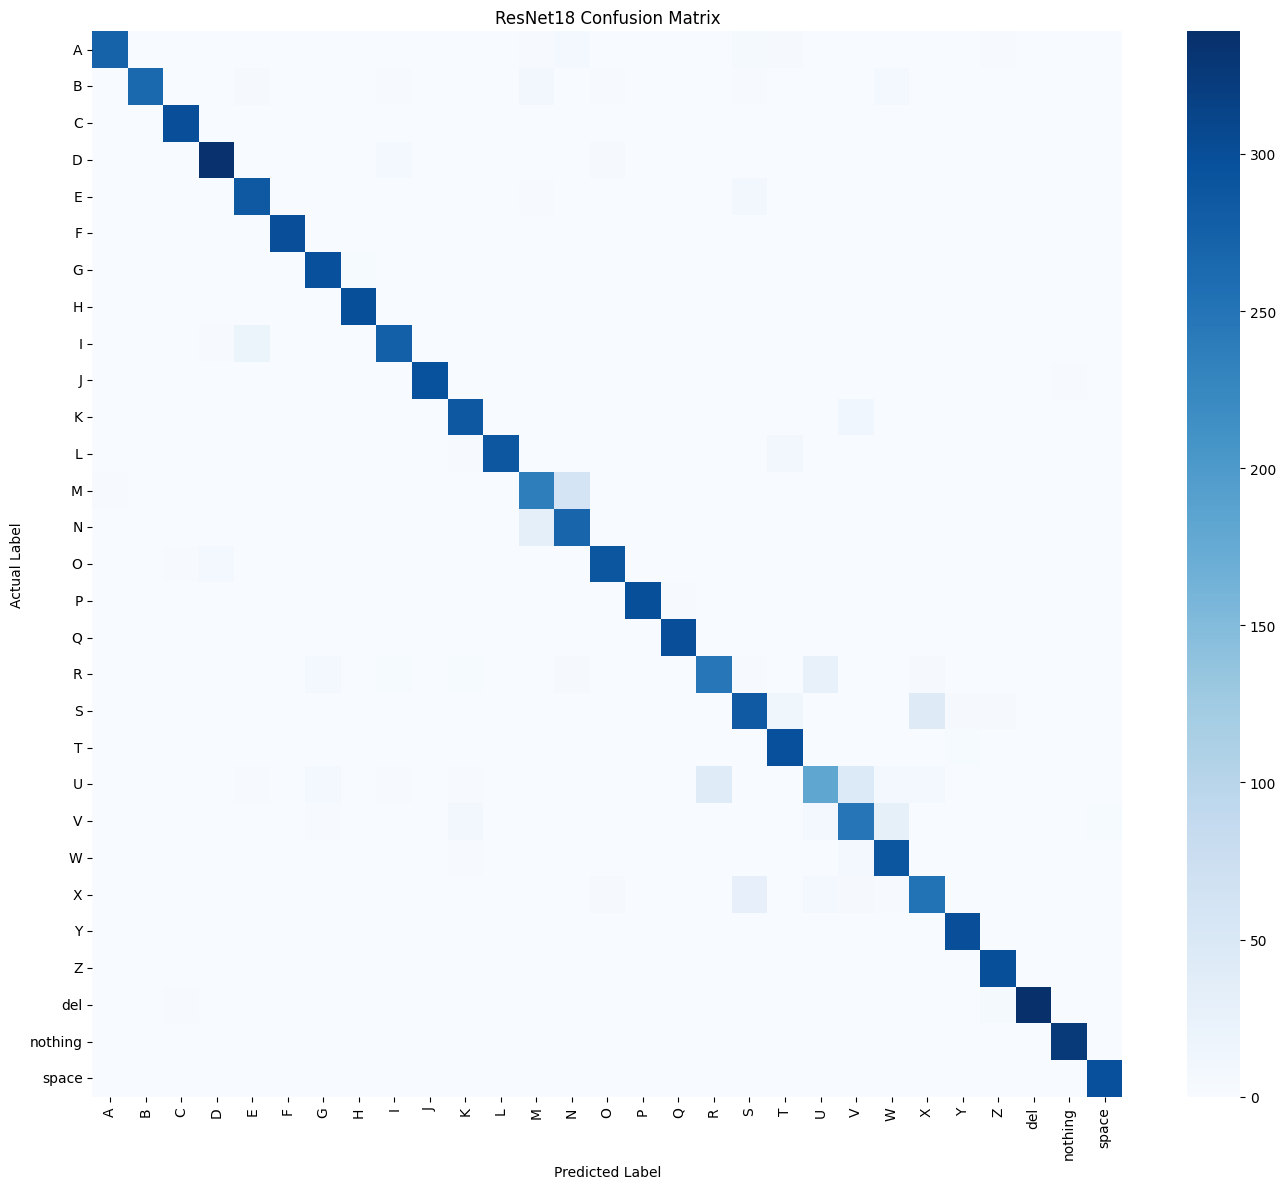

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

#class names in the same order as the dataset labels
class_names = (
    manifest[["y", "label"]]
    .drop_duplicates()
    .sort_values("y")["label"]
    .tolist()
)

#calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

#plot confusion matrix
plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 Confusion Matrix")
plt.tight_layout()
plt.show()

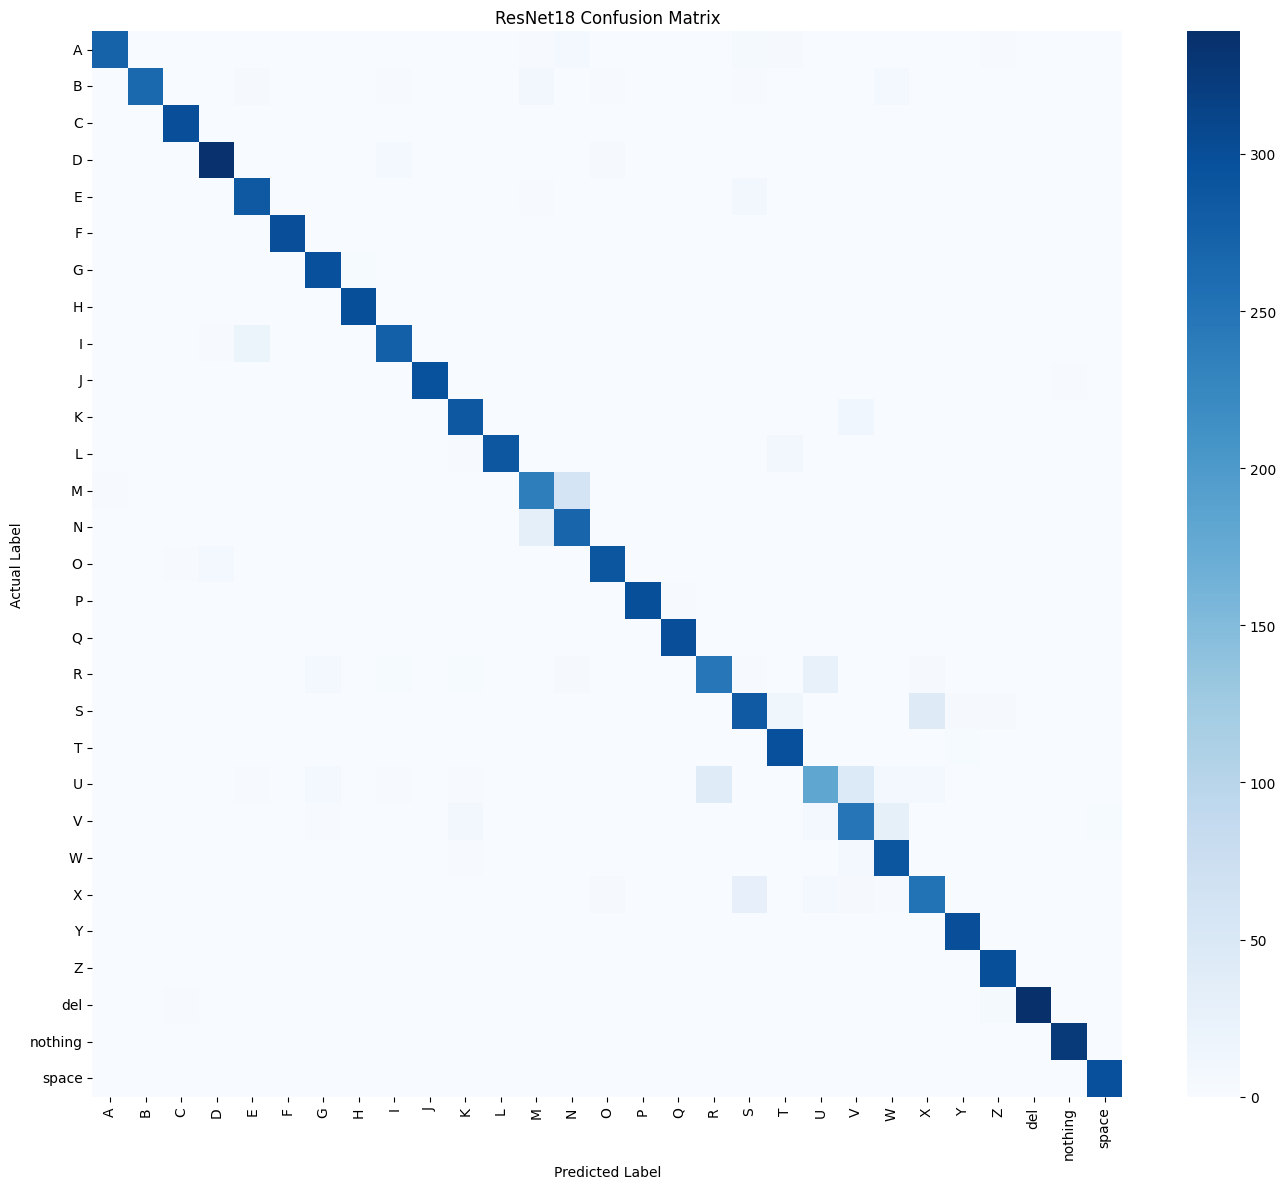

In [23]:
#save confusion matrix
plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet18 Confusion Matrix")
plt.tight_layout()

plt.savefig("resnet18_confusion_matrix.png", dpi=300)
plt.show()

MobileNetV3

In [25]:
from torchvision import models
from torch import nn

#load pretrained mobilenetv3
mobilenet = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)

#freeze pretrained layers
for param in mobilenet.parameters():
    param.requires_grad = False

#replace final layer for 29 asl classes
mobilenet.classifier[3] = nn.Linear(
    mobilenet.classifier[3].in_features,
    29
)

#move model to gpu
mobilenet = mobilenet.to(device)

print("MobileNetV3 loaded!")
print("Output classes:", mobilenet.classifier[3].out_features)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 143MB/s]

MobileNetV3 loaded!
Output classes: 29
Device: cuda


In [26]:
#setup mobilenet training
mobilenet_criterion = nn.CrossEntropyLoss()

mobilenet_optimizer = torch.optim.Adam(
    mobilenet.classifier[3].parameters(),
    lr=0.001
)

print("Loss function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Training: final classification layer only")

Loss function: CrossEntropyLoss
Optimizer: Adam
Learning rate: 0.001
Training: final classification layer only


In [ ]:
import time

#train mobilenet
epochs = 5
best_mobilenet_accuracy = 0
mobilenet_train_accuracies = []
mobilenet_val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    mobilenet.train()

    #keep frozen feature layers in evaluation mode
    mobilenet.features.eval()

    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        mobilenet_optimizer.zero_grad()

        outputs = mobilenet(images)
        loss = mobilenet_criterion(outputs, labels)

        loss.backward()
        mobilenet_optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_accuracy = train_correct / train_total
    mobilenet_train_accuracies.append(train_accuracy)

    #check validation accuracy
    mobilenet.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)

            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_accuracy = val_correct / val_total
    mobilenet_val_accuracies.append(val_accuracy)

    #save best model
    if val_accuracy > best_mobilenet_accuracy:
        best_mobilenet_accuracy = val_accuracy
        torch.save(
            mobilenet.state_dict(),
            "mobilenet_best.pth"
        )

    print(f"Epoch {epoch+1}/{epochs}")
    print(f"Training accuracy: {train_accuracy:.4f}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print()

print("Training time:", round(time.time() - start_time, 2), "seconds")
print("Best validation accuracy:", round(best_mobilenet_accuracy, 4))

Epoch 1/5
Training accuracy: 0.7606
Validation accuracy: 0.7020

